In [ ]:
# Loading the tuned Logistic Regression model and its decision threshold
import pandas as pd
import numpy as np
import joblib

model_path = "/data/netflix_churn_final_model.pkl"
model_package = joblib.load(model_path)

loaded_model = model_package["model"]
threshold = float(model_package["threshold"])

print("Model loaded successfully!")
print("Model:", model_package.get("model_name", "Logistic Regression"))
print("Decision threshold:", threshold)


Model loaded successfully!
Model: Logistic Regression
Decision threshold: 0.465


In [6]:
print(loaded_model.feature_names_in_)

['Subscription Length (Months)' 'Customer Satisfaction Score (1-10)'
 'Daily Watch Time (Hours)' 'Engagement Rate (1-10)'
 'Device Used Most Often' 'Genre Preference' 'Region'
 'Payment History (On-Time/Delayed)' 'Subscription Plan'
 'Support Queries Logged' 'Age' 'Monthly Income ($)'
 'Promotional Offers Used' 'Number of Profiles Created' 'Low_Watch_Time'
 'Low_Satisfaction' 'Low_Engagement' 'Payment_Risk' 'High_Support_Usage']


# Making a final prediction function for our model
predict_customer_churn()

In [7]:
def predict_customer_churn(customer_data, display=True):

    customer_df = pd.DataFrame([customer_data])

    # Create all engineered features used during training

    customer_df["Low_Watch_Time"] = (
        customer_df["Daily Watch Time (Hours)"] < 1
    ).astype(int)

    customer_df["Low_Engagement"] = (
        customer_df["Engagement Rate (1-10)"] <= 4
    ).astype(int)

    customer_df["Low_Satisfaction"] = (
        customer_df["Customer Satisfaction Score (1-10)"] <= 4
    ).astype(int)

    customer_df["Payment_Risk"] = (
        customer_df["Payment History (On-Time/Delayed)"]
        .astype(str).str.strip().str.lower()
        .eq("delayed").astype(int)
    )

    customer_df["High_Support_Usage"] = (
        customer_df["Support Queries Logged"] >= 3
    ).astype(int)

    # Remove non-predictor columns
    customer_df = customer_df.drop(
        columns=[
            "Customer ID",
            "Churn Status (Yes/No)",
            "Churn_Numeric"
        ],
        errors="ignore"
    )

    # Load model and threshold
    model = model_package["model"]
    threshold = model_package["threshold"]

    # Predict probability
    churn_probability = model.predict_proba(customer_df)[0, 1]

    prediction = int(churn_probability >= threshold)

    result = {
        "Prediction": "Likely to Churn" if prediction == 1 else "Likely to Stay",
        "Churn Probability": round(churn_probability * 100, 2),
        "Retention Probability": round((1 - churn_probability) * 100, 2),
        "Threshold": threshold
    }

    return result


In [8]:
# Confirm expected model features
print("Expected input features:")
print(list(loaded_model.feature_names_in_))


Expected input features:
['Subscription Length (Months)', 'Customer Satisfaction Score (1-10)', 'Daily Watch Time (Hours)', 'Engagement Rate (1-10)', 'Device Used Most Often', 'Genre Preference', 'Region', 'Payment History (On-Time/Delayed)', 'Subscription Plan', 'Support Queries Logged', 'Age', 'Monthly Income ($)', 'Promotional Offers Used', 'Number of Profiles Created', 'Low_Watch_Time', 'Low_Satisfaction', 'Low_Engagement', 'Payment_Risk', 'High_Support_Usage']


Checking sample case

In [9]:
sample_customer = {
    "Subscription Length (Months)": 12,
    "Customer Satisfaction Score (1-10)": 8,
    "Daily Watch Time (Hours)": 2.5,
    "Engagement Rate (1-10)": 8,
    "Device Used Most Often": "Smart TV",
    "Genre Preference": "Action",
    "Region": "North America",
    "Payment History (On-Time/Delayed)": "on-time",
    "Subscription Plan": "Premium",
    "Support Queries Logged": 1,
    "Age": 28,
    "Monthly Income ($)": 5000,
    "Promotional Offers Used": 2,
    "Number of Profiles Created": 3
}


In [10]:
sample_result = predict_customer_churn(sample_customer)
print(sample_result)


{'Prediction': 'Likely to Stay', 'Churn Probability': np.float64(22.01), 'Retention Probability': np.float64(77.99), 'Threshold': 0.465}


Some more Sample cases

In [11]:
customers = [
    {
        "Subscription Length (Months)": 3,
        "Customer Satisfaction Score (1-10)": 2,
        "Daily Watch Time (Hours)": 0.5,
        "Engagement Rate (1-10)": 2,
        "Device Used Most Often": "Smartphone",
        "Genre Preference": "Drama",
        "Region": "Asia-Pacific",
        "Payment History (On-Time/Delayed)": "delayed",
        "Subscription Plan": "Basic",
        "Support Queries Logged": 8,
        "Age": 22,
        "Monthly Income ($)": 20000,
        "Promotional Offers Used": 0,
        "Number of Profiles Created": 1
    },
    {
        "Subscription Length (Months)": 24,
        "Customer Satisfaction Score (1-10)": 9,
        "Daily Watch Time (Hours)": 4,
        "Engagement Rate (1-10)": 9,
        "Device Used Most Often": "Smart TV",
        "Genre Preference": "Action",
        "Region": "North America",
        "Payment History (On-Time/Delayed)": "on-time",
        "Subscription Plan": "Premium",
        "Support Queries Logged": 1,
        "Age": 30,
        "Monthly Income ($)": 60000,
        "Promotional Offers Used": 3,
        "Number of Profiles Created": 4
    },
    {
        "Subscription Length (Months)": 12,
        "Customer Satisfaction Score (1-10)": 5,
        "Daily Watch Time (Hours)": 1.5,
        "Engagement Rate (1-10)": 5,
        "Device Used Most Often": "Laptop",
        "Genre Preference": "Comedy",
        "Region": "Europe",
        "Payment History (On-Time/Delayed)": "delayed",
        "Subscription Plan": "Standard",
        "Support Queries Logged": 4,
        "Age": 35,
        "Monthly Income ($)": 35000,
        "Promotional Offers Used": 1,
        "Number of Profiles Created": 2
    }
]


In [12]:
for i, customer in enumerate(customers, start=1):
    print(f"\nCustomer {i}")
    print("-" * 35)
    print(predict_customer_churn(customer))



Customer 1
-----------------------------------
{'Prediction': 'Likely to Churn', 'Churn Probability': np.float64(98.89), 'Retention Probability': np.float64(1.11), 'Threshold': 0.465}

Customer 2
-----------------------------------
{'Prediction': 'Likely to Stay', 'Churn Probability': np.float64(8.29), 'Retention Probability': np.float64(91.71), 'Threshold': 0.465}

Customer 3
-----------------------------------
{'Prediction': 'Likely to Churn', 'Churn Probability': np.float64(86.09), 'Retention Probability': np.float64(13.91), 'Threshold': 0.465}


In [13]:
customer_4 = {
    "Subscription Length (Months)": 40,
    "Customer Satisfaction Score (1-10)": 8,
    "Daily Watch Time (Hours)": 6,
    "Engagement Rate (1-10)": 4,
    "Device Used Most Often": "Smart TV",
    "Genre Preference": "Action",
    "Region": "North America",
    "Payment History (On-Time/Delayed)": "delayed",
    "Subscription Plan": "basic",
    "Support Queries Logged": 0,
    "Age": 32,
    "Monthly Income ($)": 8000,
    "Promotional Offers Used": 2,
    "Number of Profiles Created": 1
}

predict_customer_churn(customer_4)

{'Prediction': 'Likely to Stay',
 'Churn Probability': np.float64(24.8),
 'Retention Probability': np.float64(75.2),
 'Threshold': 0.465}

In [ ]:
# Load the feature-engineered dataset used to train the model
data_path = "/data/features_engineered_data.csv"
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())


Dataset loaded successfully!
Shape: (9901, 22)
Columns: ['Customer ID', 'Subscription Length (Months)', 'Customer Satisfaction Score (1-10)', 'Daily Watch Time (Hours)', 'Engagement Rate (1-10)', 'Device Used Most Often', 'Genre Preference', 'Region', 'Payment History (On-Time/Delayed)', 'Subscription Plan', 'Churn Status (Yes/No)', 'Support Queries Logged', 'Age', 'Monthly Income ($)', 'Promotional Offers Used', 'Number of Profiles Created', 'Churn_Numeric', 'Low_Watch_Time', 'Low_Satisfaction', 'Low_Engagement', 'Payment_Risk', 'High_Support_Usage']


In [15]:
# Check target labels and convert them to numeric values
label_map = {"no": 0, "yes": 1}
y_text = df["Churn Status (Yes/No)"].astype("string").str.strip().str.lower()
y = y_text.map(label_map)

if y.isna().any():
    raise ValueError("Target contains missing or unexpected churn labels. Clean these in the Data Cleaning notebook first.")

y = y.astype(int)
print("Target distribution:")
print(y.value_counts())
print((y.value_counts(normalize=True) * 100).round(2))


Target distribution:
Churn Status (Yes/No)
0    7432
1    2469
Name: count, dtype: int64
Churn Status (Yes/No)
0    75.06
1    24.94
Name: proportion, dtype: float64


In [16]:
from sklearn.model_selection import train_test_split

# Recreate the same feature matrix and stratified split used for evaluation
X = df.drop(columns=[
    "Customer ID",
    "Churn Status (Yes/No)",
    "Churn_Numeric"
], errors="ignore")

# Ensure the engineered features exist in the dataset and match model inputs
expected_features = list(loaded_model.feature_names_in_)
missing_features = [col for col in expected_features if col not in X.columns]
if missing_features:
    raise ValueError(f"Feature-engineered CSV is missing model inputs: {missing_features}")
X = X[expected_features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (7920, 19)
Testing shape: (1981, 19)


In [17]:
# Evaluate the saved Logistic Regression model using the tuned threshold
test_probabilities = loaded_model.predict_proba(X_test)[:, list(loaded_model.classes_).index(1)]
test_predictions = (test_probabilities >= threshold).astype(int)

print("Actual test target distribution:")
print(y_test.value_counts())
print("\nPrediction distribution at threshold", threshold)
print(pd.Series(test_predictions).value_counts())


Actual test target distribution:
Churn Status (Yes/No)
0    1487
1     494
Name: count, dtype: int64

Prediction distribution at threshold 0.465
0    1006
1     975
Name: count, dtype: int64


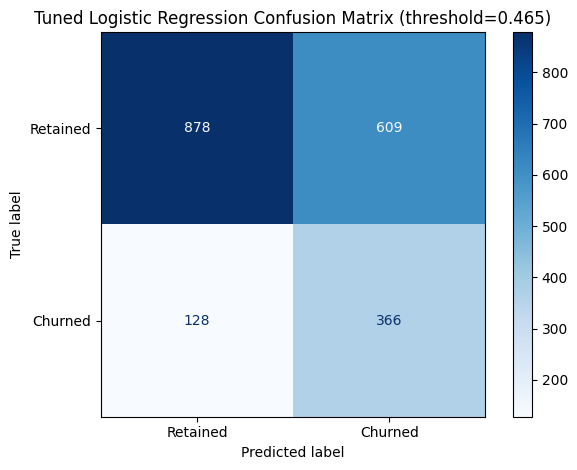

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, test_predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Retained", "Churned"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Tuned Logistic Regression Confusion Matrix (threshold={threshold:.3f})")
plt.tight_layout()
plt.show()


In [19]:
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

print(classification_report(
    y_test,
    test_predictions,
    target_names=["Retained", "Churned"],
    zero_division=0
))
print("Test accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 4))


              precision    recall  f1-score   support

    Retained       0.87      0.59      0.70      1487
     Churned       0.38      0.74      0.50       494

    accuracy                           0.63      1981
   macro avg       0.62      0.67      0.60      1981
weighted avg       0.75      0.63      0.65      1981

Test accuracy: 0.628
Test ROC-AUC: 0.7303


In [20]:
# Extract coefficients from the fitted Logistic Regression pipeline
preprocessor = loaded_model.named_steps["preprocessor"]
classifier = loaded_model.named_steps["classifier"]
feature_names = preprocessor.get_feature_names_out()
coefficients = classifier.coef_[0]

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute Coefficient": np.abs(coefficients)
}).sort_values("Absolute Coefficient", ascending=False)

print(coefficient_df.to_string(index=False))


                                       Feature  Coefficient  Absolute Coefficient
       num__Customer Satisfaction Score (1-10)    -0.598558              0.598558
                   num__Engagement Rate (1-10)    -0.408099              0.408099
                 num__Daily Watch Time (Hours)    -0.343198              0.343198
             num__Subscription Length (Months)    -0.231376              0.231376
                   num__Support Queries Logged     0.220361              0.220361
            cat__Device Used Most Often_Tablet    -0.200560              0.200560
                             num__Payment_Risk     0.169624              0.169624
cat__Payment History (On-Time/Delayed)_on-time    -0.131504              0.131504
               cat__Subscription Plan_standard    -0.108664              0.108664
                       num__Monthly Income ($)    -0.093026              0.093026
            cat__Device Used Most Often_Laptop     0.089727              0.089727
                

In [21]:
# Correlation of numeric features with churn (descriptive analysis only)
correlation = df.corr(numeric_only=True)["Churn_Numeric"]
correlation = correlation.drop("Churn_Numeric", errors="ignore").sort_values(
    key=lambda values: values.abs(), ascending=False
)
print("Correlation with churn:")
print(correlation)


Correlation with churn:
Customer Satisfaction Score (1-10)   -0.217857
Engagement Rate (1-10)               -0.215192
Daily Watch Time (Hours)             -0.191354
Low_Engagement                        0.178023
Low_Satisfaction                      0.136568
Low_Watch_Time                        0.133424
Payment_Risk                          0.104298
Subscription Length (Months)         -0.099971
Support Queries Logged                0.090408
High_Support_Usage                    0.069386
Monthly Income ($)                   -0.027432
Number of Profiles Created            0.010910
Promotional Offers Used               0.009805
Age                                  -0.003524
Name: Churn_Numeric, dtype: float64


In [22]:
categorical_columns = [
    "Device Used Most Often", "Genre Preference", "Region",
    "Payment History (On-Time/Delayed)", "Subscription Plan"
]

for col in categorical_columns:
    print(f"\nChurn distribution by {col}:")
    print(pd.crosstab(df[col], y, normalize="index").mul(100).round(2))



Churn distribution by Device Used Most Often:
Churn Status (Yes/No)       0      1
Device Used Most Often              
Laptop                  74.06  25.94
Smart Tv                75.03  24.97
Smartphone              74.78  25.22
Tablet                  78.02  21.98

Churn distribution by Genre Preference:
Churn Status (Yes/No)      0      1
Genre Preference                   
action                 75.53  24.47
comedy                 75.07  24.93
documentary            74.79  25.21
drama                  75.75  24.25
sci-fi                 73.59  26.41
thriller               75.63  24.37

Churn distribution by Region:
Churn Status (Yes/No)      0      1
Region                             
asia-pacific           75.12  24.88
europe                 74.74  25.26
latin-america          75.84  24.16
north-america          74.98  25.02

Churn distribution by Payment History (On-Time/Delayed):
Churn Status (Yes/No)                  0      1
Payment History (On-Time/Delayed)              
d

In [23]:
print("Model:", model_package.get("model_name", "Logistic Regression"))
print("Decision threshold:", threshold)
print("\nModel input columns:")
print(list(loaded_model.feature_names_in_))


Model: Logistic Regression
Decision threshold: 0.465

Model input columns:
['Subscription Length (Months)', 'Customer Satisfaction Score (1-10)', 'Daily Watch Time (Hours)', 'Engagement Rate (1-10)', 'Device Used Most Often', 'Genre Preference', 'Region', 'Payment History (On-Time/Delayed)', 'Subscription Plan', 'Support Queries Logged', 'Age', 'Monthly Income ($)', 'Promotional Offers Used', 'Number of Profiles Created', 'Low_Watch_Time', 'Low_Satisfaction', 'Low_Engagement', 'Payment_Risk', 'High_Support_Usage']


In [24]:
# Churn probability distribution on the held-out test set
print("Churn Probability Statistics:")
print(pd.Series(test_probabilities).describe())
print("\nFirst 10 churn probabilities:")
print(test_probabilities[:10])


Churn Probability Statistics:
count    1981.000000
mean        0.460526
std         0.205047
min         0.016107
25%         0.297625
50%         0.460922
75%         0.619412
max         0.984124
dtype: float64

First 10 churn probabilities:
[0.23422298 0.5622574  0.42328686 0.53938651 0.55236836 0.85285374
 0.51158243 0.18604002 0.12026151 0.0969321 ]


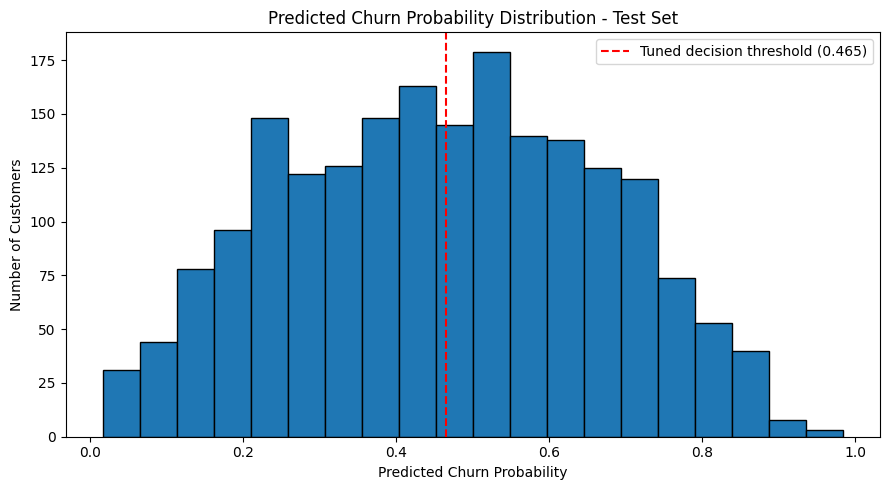

In [25]:
plt.figure(figsize=(9, 5))
plt.hist(test_probabilities, bins=20, edgecolor="black")
plt.axvline(
    threshold, color="red", linestyle="--",
    label=f"Tuned decision threshold ({threshold:.3f})"
)
plt.title("Predicted Churn Probability Distribution - Test Set")
plt.xlabel("Predicted Churn Probability")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()


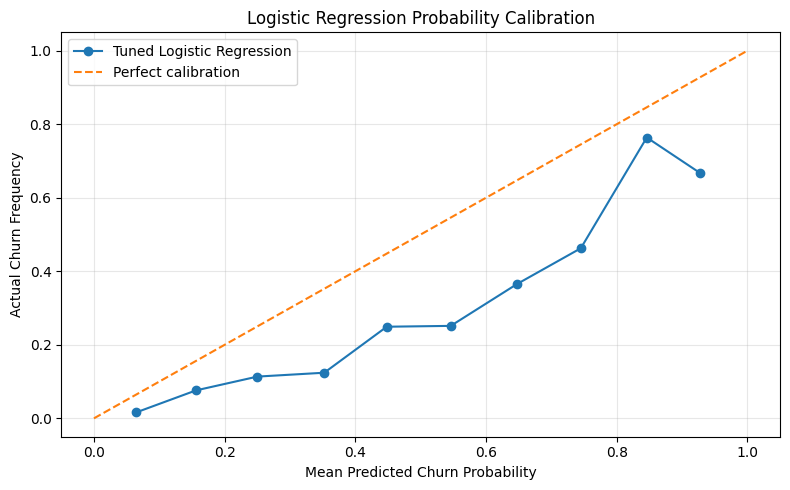

In [26]:
from sklearn.calibration import calibration_curve

actual_fraction, predicted_mean = calibration_curve(
    y_test, test_probabilities, n_bins=10, strategy="uniform"
)

plt.figure(figsize=(8, 5))
plt.plot(predicted_mean, actual_fraction, marker="o", label="Tuned Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean Predicted Churn Probability")
plt.ylabel("Actual Churn Frequency")
plt.title("Logistic Regression Probability Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [27]:
# Brier score: lower values indicate better probability accuracy
from sklearn.metrics import brier_score_loss

print("Logistic Regression Brier Score:", round(
    brier_score_loss(y_test, test_probabilities), 4
))


Logistic Regression Brier Score: 0.2113


In [28]:
# Summary of final test-set metrics at the tuned threshold
from sklearn.metrics import precision_score, recall_score, f1_score

final_metrics = pd.DataFrame([{
    "Model": "Tuned Logistic Regression",
    "Threshold": threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1-Score": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Brier Score": brier_score_loss(y_test, test_probabilities)
}])

print(final_metrics.round(4).to_string(index=False))


                    Model  Threshold  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Brier Score
Tuned Logistic Regression      0.465     0.628     0.3754  0.7409    0.4983   0.7303       0.2113


In [29]:
# Compare calibration curve and threshold interpretation
print(f"A customer is classified as at risk when predicted churn probability >= {threshold:.3f}.")
print("The probability itself is a model estimate, not a guarantee that a customer will churn.")


A customer is classified as at risk when predicted churn probability >= 0.465.
The probability itself is a model estimate, not a guarantee that a customer will churn.


In [30]:
result = predict_customer_churn(sample_customer)

In [31]:
predict_customer_churn(sample_customer)


{'Prediction': 'Likely to Stay',
 'Churn Probability': np.float64(22.01),
 'Retention Probability': np.float64(77.99),
 'Threshold': 0.465}

In [32]:
for i, customer in enumerate(customers, start=1):
    print(f"\nCustomer {i}")
    print("-" * 35)
    print(predict_customer_churn(customer))



Customer 1
-----------------------------------
{'Prediction': 'Likely to Churn', 'Churn Probability': np.float64(98.89), 'Retention Probability': np.float64(1.11), 'Threshold': 0.465}

Customer 2
-----------------------------------
{'Prediction': 'Likely to Stay', 'Churn Probability': np.float64(8.29), 'Retention Probability': np.float64(91.71), 'Threshold': 0.465}

Customer 3
-----------------------------------
{'Prediction': 'Likely to Churn', 'Churn Probability': np.float64(86.09), 'Retention Probability': np.float64(13.91), 'Threshold': 0.465}


In [33]:

# Display a structured prediction table for sample customers

sample_results = []

for i, customer in enumerate(customers, start=1):

    result = predict_customer_churn(customer, display=False)

    sample_results.append({
        "Customer": i,
        "Prediction": result["Prediction"],
        "Churn Probability (%)": result["Churn Probability"],
        "Retention Probability (%)": result["Retention Probability"],
        "Threshold": result["Threshold"]
    })

sample_results_df = pd.DataFrame(sample_results)

display(sample_results_df)


,Customer,Prediction,Churn Probability (%),Retention Probability (%),Threshold
0,1,Likely to Churn,98.89,1.11,0.465
1,2,Likely to Stay,8.29,91.71,0.465
2,3,Likely to Churn,86.09,13.91,0.465


In [34]:
# Compare sample customer values with dataset statistics
numeric_columns = [
    "Subscription Length (Months)",
    "Customer Satisfaction Score (1-10)",
    "Daily Watch Time (Hours)",
    "Engagement Rate (1-10)",
    "Support Queries Logged",
    "Age",
    "Monthly Income ($)",
    "Promotional Offers Used",
    "Number of Profiles Created"
]
print("Dataset statistics:")
print(df[numeric_columns].describe().round(2))


Dataset statistics:
       Subscription Length (Months)  Customer Satisfaction Score (1-10)  \
count                       9901.00                             9901.00   
mean                          36.46                                6.98   
std                           20.71                                1.73   
min                            1.00                                1.00   
25%                           19.00                                6.00   
50%                           36.00                                7.00   
75%                           54.00                                8.00   
max                           72.00                               10.00   

       Daily Watch Time (Hours)  Engagement Rate (1-10)  \
count                   9901.00                 9901.00   
mean                       2.07                    4.11   
std                        1.43                    1.91   
min                        0.05                    1.00   
25%      

In [35]:
print("Churn distribution by satisfaction:")
print(pd.crosstab(
    pd.cut(df["Customer Satisfaction Score (1-10)"], bins=[0, 3, 6, 8, 10]),
    y, normalize="index"
).mul(100).round(2))

print("\nChurn distribution by engagement:")
print(pd.crosstab(df["Engagement Rate (1-10)"], y, normalize="index").mul(100).round(2))


Churn distribution by satisfaction:
Churn Status (Yes/No)                   0      1
Customer Satisfaction Score (1-10)              
(0, 3]                              46.96  53.04
(3, 6]                              66.28  33.72
(6, 8]                              78.03  21.97
(8, 10]                             87.61  12.39

Churn distribution by engagement:
Churn Status (Yes/No)       0      1
Engagement Rate (1-10)              
1.0                     56.50  43.50
2.0                     64.46  35.54
3.0                     70.11  29.89
4.0                     75.21  24.79
5.0                     82.51  17.49
6.0                     82.42  17.58
7.0                     87.64  12.36
8.0                     92.70   7.30
9.0                     96.61   3.39
10.0                    96.25   3.75


In [36]:
# Churn rate by subscription length
print("Churn by Subscription Length:")
print(pd.crosstab(df["Subscription Length (Months)"], y, normalize="index").mul(100).round(2))

# Churn rate by age group
df["Age_Group"] = pd.cut(
    df["Age"], bins=[17, 25, 35, 45, 55, 70],
    labels=["18-25", "26-35", "36-45", "46-55", "56-70"]
)
print("\nChurn by Age Group:")
print(pd.crosstab(df["Age_Group"], y, normalize="index").mul(100).round(2))


Churn by Subscription Length:
Churn Status (Yes/No)             0      1
Subscription Length (Months)              
1.0                           67.20  32.80
2.0                           68.28  31.72
3.0                           69.18  30.82
4.0                           66.38  33.62
5.0                           71.32  28.68
...                             ...    ...
68.0                          85.94  14.06
69.0                          81.58  18.42
70.0                          80.82  19.18
71.0                          88.55  11.45
72.0                          79.10  20.90

[72 rows x 2 columns]

Churn by Age Group:
Churn Status (Yes/No)      0      1
Age_Group                          
18-25                  73.38  26.62
26-35                  75.99  24.01
36-45                  75.36  24.64
46-55                  74.16  25.84
56-70                  76.32  23.68


In [37]:
print("Customer count by subscription length:")
print(df["Subscription Length (Months)"].value_counts().sort_index())

print("\nCustomer count by age group:")
print(df["Age_Group"].value_counts().sort_index())


Customer count by subscription length:
Subscription Length (Months)
1.0     125
2.0     145
3.0     159
4.0     116
5.0     136
       ... 
68.0    128
69.0    152
70.0    146
71.0    131
72.0    134
Name: count, Length: 72, dtype: int64

Customer count by age group:
Age_Group
18-25    1743
26-35    3057
36-45    3235
46-55    1486
56-70     380
Name: count, dtype: int64


In [38]:

# 10 diverse customer test cases

customers = [

    {**sample_customer,
     "Customer Satisfaction Score (1-10)": 9,
     "Daily Watch Time (Hours)": 5.5,
     "Engagement Rate (1-10)": 9,
     "Payment History (On-Time/Delayed)": "On-Time",
     "Support Queries Logged": 0},

    {**sample_customer,
     "Customer Satisfaction Score (1-10)": 2,
     "Daily Watch Time (Hours)": 0.5,
     "Engagement Rate (1-10)": 2,
     "Payment History (On-Time/Delayed)": "Delayed",
     "Support Queries Logged": 8},

    {**sample_customer,
     "Customer Satisfaction Score (1-10)": 8,
     "Daily Watch Time (Hours)": 4.5,
     "Engagement Rate (1-10)": 8,
     "Payment History (On-Time/Delayed)": "On-Time",
     "Support Queries Logged": 1},

    {**sample_customer,
     "Customer Satisfaction Score (1-10)": 3,
     "Daily Watch Time (Hours)": 0.8,
     "Engagement Rate (1-10)": 3,
     "Payment History (On-Time/Delayed)": "Delayed",
     "Support Queries Logged": 7},

    {**sample_customer,
     "Customer Satisfaction Score (1-10)": 6,
     "Daily Watch Time (Hours)": 2.5,
     "Engagement Rate (1-10)": 6,
     "Payment History (On-Time/Delayed)": "On-Time",
     "Support Queries Logged": 2},

    {**sample_customer,
     "Customer Satisfaction Score (1-10)": 4,
     "Daily Watch Time (Hours)": 1.0,
     "Engagement Rate (1-10)": 3,
     "Payment History (On-Time/Delayed)": "Delayed",
     "Support Queries Logged": 5},

    {**sample_customer,
     "Customer Satisfaction Score (1-10)": 10,
     "Daily Watch Time (Hours)": 6.0,
     "Engagement Rate (1-10)": 10,
     "Payment History (On-Time/Delayed)": "On-Time",
     "Support Queries Logged": 0},

    {**sample_customer,
     "Customer Satisfaction Score (1-10)": 5,
     "Daily Watch Time (Hours)": 1.5,
     "Engagement Rate (1-10)": 5,
     "Payment History (On-Time/Delayed)": "Delayed",
     "Support Queries Logged": 4},

    {**sample_customer,
     "Customer Satisfaction Score (1-10)": 7,
     "Daily Watch Time (Hours)": 3.5,
     "Engagement Rate (1-10)": 7,
     "Payment History (On-Time/Delayed)": "On-Time",
     "Support Queries Logged": 1},

    {**sample_customer,
     "Customer Satisfaction Score (1-10)": 1,
     "Daily Watch Time (Hours)": 0.3,
     "Engagement Rate (1-10)": 1,
     "Payment History (On-Time/Delayed)": "Delayed",
     "Support Queries Logged": 9}
]



In [39]:

# Predicting churn for all 10 customers

sample_results = []

for i, customer in enumerate(customers, start=1):

    result = predict_customer_churn(customer, display=False)

    sample_results.append({
        "Customer": f"C{i}",
        "Prediction": result["Prediction"],
        "Churn Probability (%)": result["Churn Probability"],
        "Retention Probability (%)": result["Retention Probability"],
        "Threshold": result["Threshold"]
    })

sample_results_df = pd.DataFrame(sample_results)

display(sample_results_df)


,Customer,Prediction,Churn Probability (%),Retention Probability (%),Threshold
0,C1,Likely to Stay,6.92,93.08,0.465
1,C2,Likely to Churn,98.82,1.18,0.465
2,C3,Likely to Stay,16.59,83.41,0.465
3,C4,Likely to Churn,97.38,2.62,0.465
4,C5,Likely to Churn,54.22,45.78,0.465
5,C6,Likely to Churn,94.38,5.62,0.465
6,C7,Likely to Stay,3.63,96.37,0.465
7,C8,Likely to Churn,85.64,14.36,0.465
8,C9,Likely to Stay,30.69,69.31,0.465
9,C10,Likely to Churn,99.46,0.54,0.465


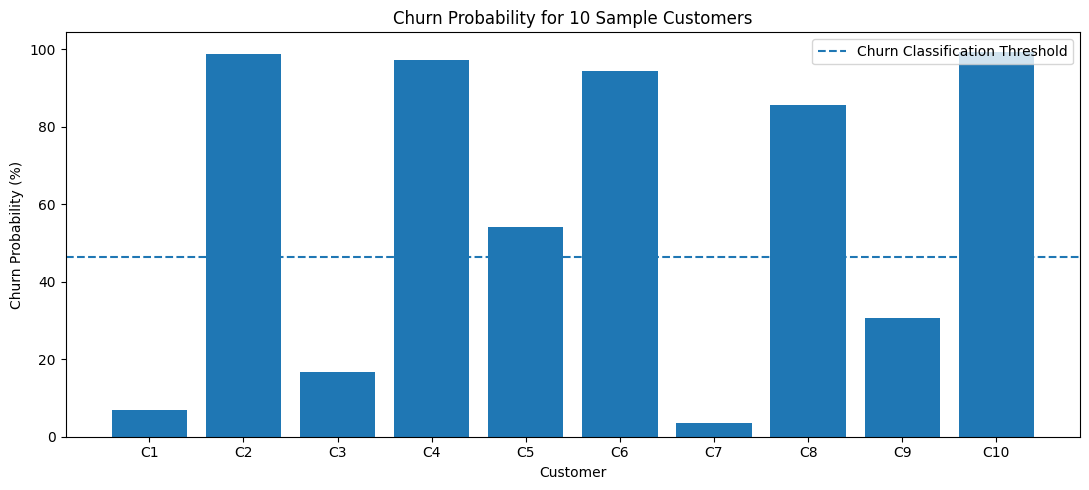

In [40]:
# Visualising the predicted results
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.bar(
    sample_results_df["Customer"],
    sample_results_df["Churn Probability (%)"]
)

plt.axhline(
    y=sample_results_df["Threshold"].iloc[0] * 100,
    linestyle="--",
    label="Churn Classification Threshold"
)

plt.xlabel("Customer")
plt.ylabel("Churn Probability (%)")
plt.title("Churn Probability for 10 Sample Customers")
plt.legend()
plt.tight_layout()
plt.show()


Our Final Function is **predict_customer_churn()**